# FIT TRADIZIONALE con multi-start Monte Carlo


---

La funzione di fit è la somma di due lorentziane con un'ampiezza di offset: in totale 7 parametri.

In [1]:
def due_lorentziane(f, A0, A1, x1, w1, A2, x2, w2):
    """
    Funzione che calcola la somma di due lorentziane.
    f:  array di frequenze
    A0: ampiezza di offset
    A1: ampiezza della prima lorentziana
    x1: centro della prima lorentziana
    w1: larghezza della prima lorentziana
    A2: ampiezza della seconda lorentziana
    x2: centro della seconda lorentziana
    w2: larghezza della seconda lorentziana
    """
    
    def lorentziana(f, A, x, w):
        return A * (w**2 / ((f - x) ** 2 + w**2))
    
    lorentziana1 = lorentziana(f, A1, x1, w1)
    lorentziana2 = lorentziana(f, A2, x2, w2)
    
    return A0 - lorentziana1 - lorentziana2

Quando lo spettro da interpolare è molto rumoroso, non esiste una tecnica consistente e sempre valida per inizializzare i parametri. 

Si ricorre al multi-start Monte Carlo: vengono generati $M$ vettori dei parametri in dei boundaries fisicamente sensati, si esegue il fit per ciascun vettore, quindi si selezionano quei parametri che realizzano il minor scarto quadratico normalizzato (minimo chi quadro).

In [2]:
M = 20 # numero di vettori di parametri da generare

In [3]:
import numpy as np

# Limiti fisici
low_x = 2.75
upp_x = 2.95

low_a = 0
upp_a = 1e3

low_w = 0
upp_w = 0.2

bounds = {
    'A': (low_a, upp_a),
    'x': (low_x, upp_x),
    'w': (low_w, upp_w)
}

In [4]:
def random_vector(bounds):
    low_a, upp_a = bounds['A']
    low_x, upp_x = bounds['x']
    low_w, upp_w = bounds['w']

    A0 = np.random.uniform(low_a,upp_a)
    x1 = np.random.uniform(low_x,upp_x)
    A1 = np.random.uniform(low_a,upp_a)
    w1 = np.random.uniform(low_w,upp_w)
    x2 = np.random.uniform(low_x,upp_x)
    A2 = np.random.uniform(low_a,upp_a)
    w2 = np.random.uniform(low_w,upp_w)

    return A0, A1, x1, w1, A2, x2, w2

In [5]:
from scipy.optimize import curve_fit

def fit_due_lorentziane(f, y, p0):
    # eseguo il fit
    popt, pcov = curve_fit(due_lorentziane, f, y, p0=p0)
    return popt, pcov

def compute_chi_squared(f, y, popt):
    # calcolo i valori previsti dalla funzione con i parametri ottimizzati
    y_fit = due_lorentziane(f, *popt)
    # errore poissoniano
    y_err = np.sqrt(y)
    # calcolo il chi-quadrato
    chi_squared = np.sum((y - y_fit) ** 2 / y_err)
    return chi_squared

def fit_and_select(f, y):
    
    best_chi_squared = np.inf
    best_p0 = None
    
    for i in range(M):
        # genero un vettore di parametri iniziali casuali
        p0 = random_vector(bounds=bounds)
        popt, pcov = fit_due_lorentziane(f, y, p0)
        chi_squared = compute_chi_squared(f, y, popt)
        
        if chi_squared < best_chi_squared:
            best_p0 = popt
            best_chi_squared = chi_squared
        
    return best_p0, best_chi_squared
    

Leggo gli spettri

In [6]:
import h5py

# Percorso del file generato da EasySpin
file_path = "../data/10k/odmr_easyspin_raw_10000.mat"

# Lettura tramite h5py (standard per MAT-file v7.3)
with h5py.File(file_path, "r") as f:
    # MATLAB salva i dataset trasposti (colonna-prioritaria vs riga-prioritaria)
    # Applichiamo .T per ripristinare la forma corretta: [N_spettri, N_punti]
    spectra_data = np.array(f["spectra_data"]).T
    labels_B = np.array(f["labels_B"]).squeeze()
    labels_D = np.array(f["labels_D"]).squeeze()
    labels_lw = np.array(f["labels_lw"]).squeeze()
    labels_c = np.array(f["labels_c"]).squeeze()
    labels_s = np.array(f["labels_s"]).squeeze()
    mw_freqs = np.array(f["mw_freqs"]).squeeze()

---

In [7]:
import numpy as np
from scipy.optimize import curve_fit

# Modello a 2 lorentziane su fondo unitario (per spettri con PL e dip verso il basso)
def double_lorentzian(f, A0, A1, x1, w1, A2, x2, w2):
    return A0 - A1 * (w1**2 / ((f - x1)**2 + w1**2)) - A2 * (w2**2 / ((f - x2)**2 + w2**2))

def fit_odmr_spectrum(f_ghz, counts, M=20):
    """
    Fit multi-start Monte Carlo su conteggi di fotoni reali.
    f_ghz: asse frequenze (es. [2.75, 2.95])
    counts: vettore 1D di conteggi di fotoni poissoniani misurati
    """
    # 1. Stima del fondo e deviazione standard shot noise
    A0_est = np.percentile(counts, 90)
    sigma = np.sqrt(np.maximum(counts, 1.0))
    
    f_min, f_max = f_ghz.min(), f_ghz.max()
    
    # 2. Bound fisici stretti basati sulla fisica del centro NV:
    # A0: vicino al fondo
    # A1, A2: contrasto ottico (tra 1% e 20% del fondo)
    # x1, x2: all'interno della finestra di risonanza
    # w1, w2: larghezze fisiche FWHM (es. 2 - 15 MHz -> 0.002 - 0.015 GHz)
    bounds_lower = [0.8 * A0_est, 0.005 * A0_est, f_min, 0.002, 0.005 * A0_est, f_min, 0.002]
    bounds_upper = [1.2 * A0_est, 0.250 * A0_est, f_max, 0.020, 0.250 * A0_est, f_max, 0.020]
    
    best_popt = None
    best_chi2 = np.inf
    
    for _ in range(M):
        # Campionamento mirato delle guess iniziali
        p0 = [
            np.random.uniform(0.95 * A0_est, 1.05 * A0_est),
            np.random.uniform(0.02 * A0_est, 0.15 * A0_est),
            np.random.uniform(2.82, 2.87),                     # dip sinistro
            np.random.uniform(0.004, 0.010),                   # FWHM ~6 MHz
            np.random.uniform(0.02 * A0_est, 0.15 * A0_est),
            np.random.uniform(2.87, 2.92),                     # dip destro
            np.random.uniform(0.004, 0.010)
        ]
        
        try:
            popt, _ = curve_fit(
                double_lorentzian,
                f_ghz,
                counts,
                p0=p0,
                bounds=(bounds_lower, bounds_upper),
                sigma=sigma,
                maxfev=2000
            )
            
            res = (counts - double_lorentzian(f_ghz, *popt)) / sigma
            chi2 = np.sum(res**2)
            
            if chi2 < best_chi2:
                best_chi2 = chi2
                best_popt = popt
        except (RuntimeError, ValueError):
            continue
            
    if best_popt is None:
        return np.full(7, np.nan), np.inf
    
    # Ordiniamo i due dip per convenzione (x1 < x2)
    if best_popt[2] > best_popt[5]:
        best_popt = [best_popt[0], best_popt[4], best_popt[5], best_popt[6], 
                                  best_popt[1], best_popt[2], best_popt[3]]
        
    return best_popt, best_chi2

ID   | N_tot    | True (c, s)      | Fit (c, s)       | Err c    | Err s    | Chi2_red
--------------------------------------------------------------------------------
#0   | 5.0e+06  | (0.6073, 0.1075) | (0.6068, 0.1092) | 0.0005   | 0.0017   | 0.09    
#15  | 5.0e+06  | (0.5485, 0.1037) | (0.5505, 0.1025) | 0.0021   | 0.0012   | 0.05    
#42  | 5.0e+06  | (0.4755, 0.1033) | (0.4750, 0.1055) | 0.0005   | 0.0022   | 0.08    
#88  | 3.5e+05  | (0.4780, 0.1022) | (0.4751, 0.1017) | 0.0028   | 0.0005   | 0.57    
#120 | 3.5e+05  | (0.4663, 0.1046) | (0.4565, 0.0951) | 0.0098   | 0.0095   | 0.43    
#250 | 3.5e+05  | (0.5422, 0.1008) | (0.5358, 0.0993) | 0.0064   | 0.0015   | 0.36    


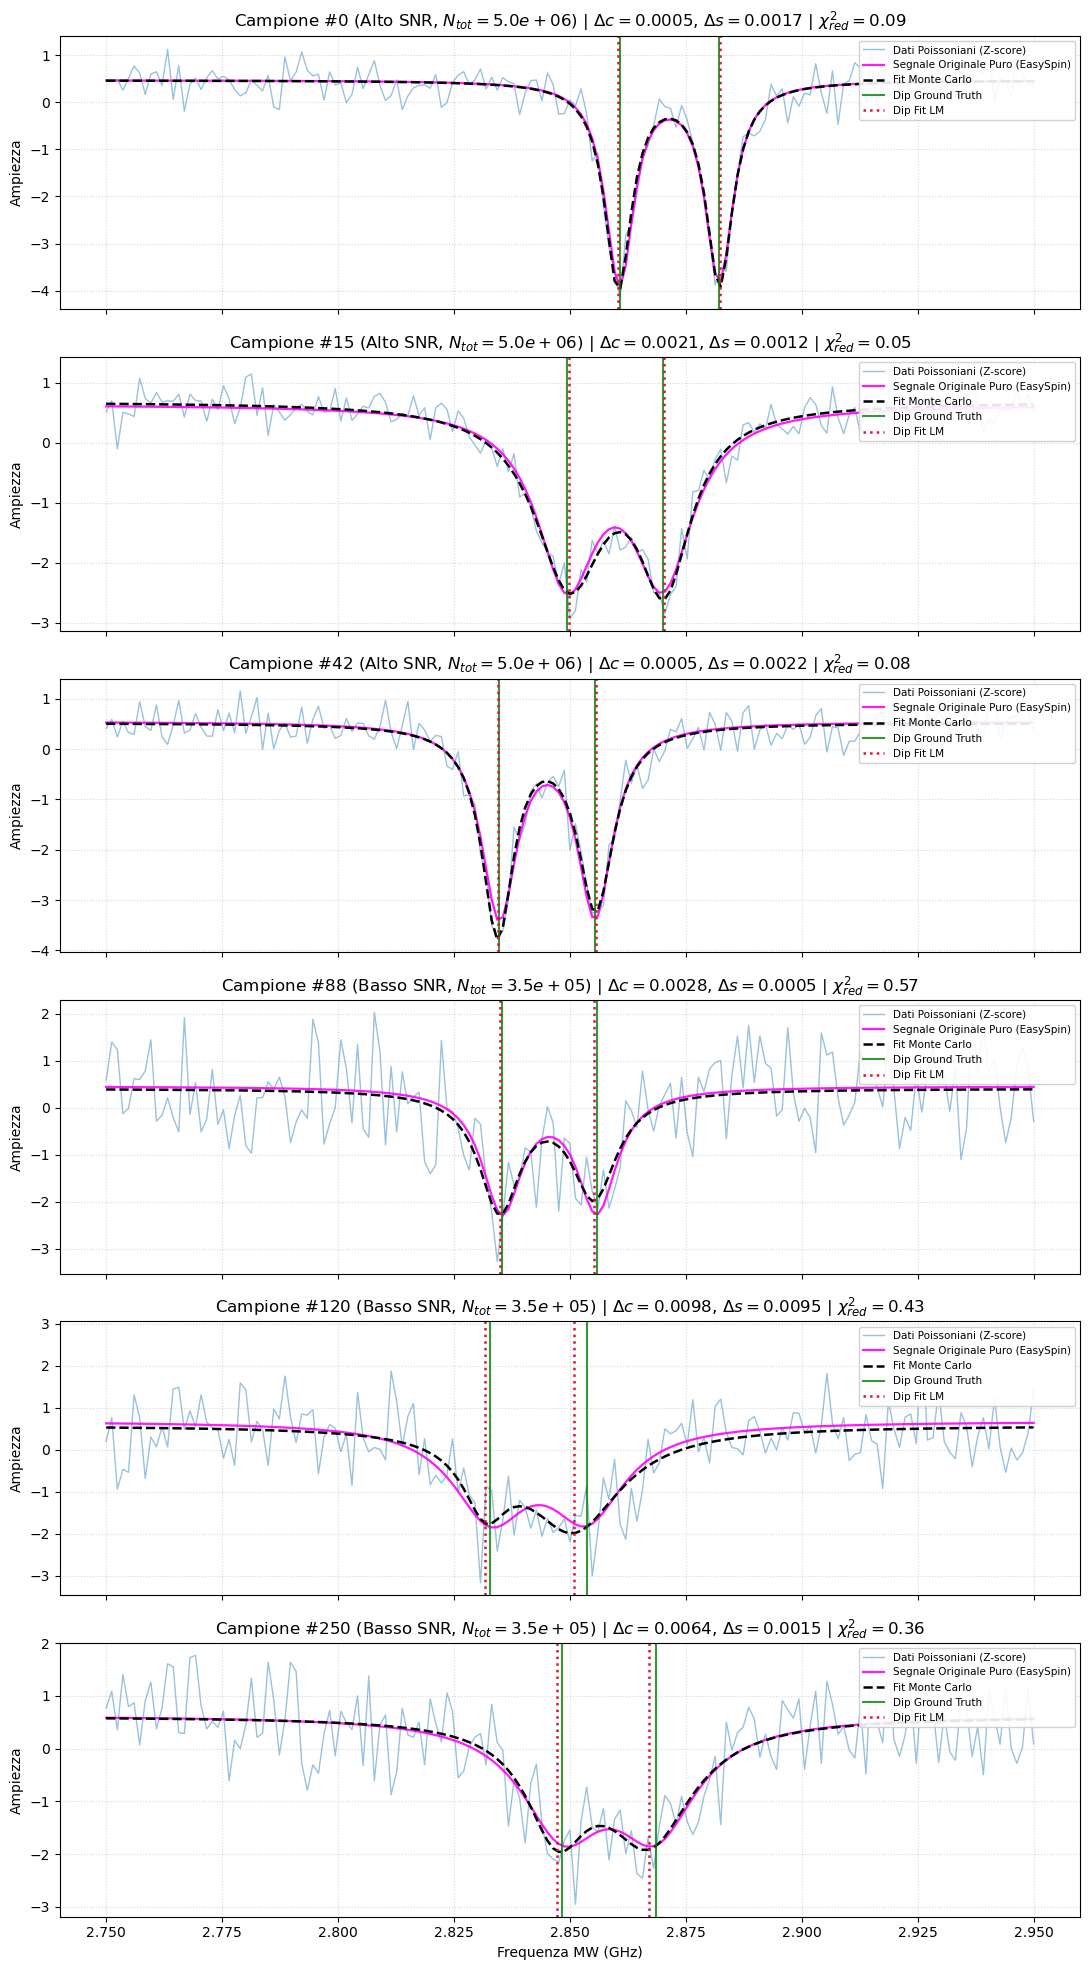

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# =========================================================================
# 1. MODELLO A DUE LORENTZIANE (SU SPETTRO STANDARDIZZATO Z-SCORE)
# =========================================================================
def due_lorentziane_zscore(f, A0, A1, x1, w1, A2, x2, w2):
    """
    Modello a due dip lorentziani verso il basso su segnale Z-score.
    f: frequenza in GHz
    A0: offset di fondo
    A1, A2: profondità dei dip
    x1, x2: posizioni centrali dei dip (GHz)
    w1, w2: semilarghezze HWHM (GHz)
    """
    return (
        A0
        - A1 * (w1**2 / ((f - x1)**2 + w1**2))
        - A2 * (w2**2 / ((f - x2)**2 + w2**2))
    )

def fit_odmr_monte_carlo(f_ghz, y_zscore, M=20):
    """
    Esegue il fit multi-start Monte Carlo su un singolo spettro rumoroso.
    Restituisce: (c_fit, s_fit, popt, chi2_red)
    """
    f_min, f_max = float(f_ghz.min()), float(f_ghz.max())
    delta_f = f_max - f_min
    N_points = len(f_ghz)
    n_params = 7

    # Stime preliminari per circoscrivere lo spazio di ricerca
    A0_est = np.percentile(y_zscore, 85)
    dip_depth_est = max(A0_est - np.min(y_zscore), 0.5)

    # Limiti fisici (bounds):
    # w: HWHM tra 1.5 MHz e 15 MHz (0.0015 - 0.015 GHz)
    lower = [A0_est - 2.5, 0.05, f_min, 0.0015, 0.05, f_min, 0.0015]
    upper = [A0_est + 2.5, dip_depth_est * 2.5, f_max, 0.0150, dip_depth_est * 2.5, f_max, 0.0150]

    best_popt = None
    best_chi2 = np.inf

    for _ in range(M):
        # Campionamento Monte Carlo dei parametri di partenza (guess p0)
        p0 = [
            np.random.uniform(A0_est - 0.5, A0_est + 0.5),
            np.random.uniform(0.3, dip_depth_est),
            np.random.uniform(2.81, 2.86),    # candidato dip sinistro
            np.random.uniform(0.003, 0.008),  # HWHM tipica ~4-6 MHz
            np.random.uniform(0.3, dip_depth_est),
            np.random.uniform(2.86, 2.91),    # candidato dip destro
            np.random.uniform(0.003, 0.008)
        ]

        try:
            popt, _ = curve_fit(
                due_lorentziane_zscore,
                f_ghz,
                y_zscore,
                p0=p0,
                bounds=(lower, upper),
                maxfev=3000
            )
            residuals = y_zscore - due_lorentziane_zscore(f_ghz, *popt)
            chi2 = np.sum(residuals**2)

            if chi2 < best_chi2:
                best_chi2 = chi2
                best_popt = popt
        except (RuntimeError, ValueError):
            continue

    if best_popt is None:
        return np.nan, np.nan, None, np.inf

    # Ordinamento dei dip (x1 < x2)
    x1_fit, x2_fit = best_popt[2], best_popt[5]
    if x1_fit > x2_fit:
        x1_fit, x2_fit = x2_fit, x1_fit

    # Proiezione delle coordinate stimate nello spazio adimensionale [0, 1]
    x1_norm = (x1_fit - f_min) / delta_f
    x2_norm = (x2_fit - f_min) / delta_f
    c_fit = (x1_norm + x2_norm) / 2.0
    s_fit = x2_norm - x1_norm

    chi2_red = best_chi2 / (N_points - n_params)
    return c_fit, s_fit, best_popt, chi2_red


# =========================================================================
# 2. ESECUZIONE DEL TEST SU SPETTRI SELEZIONATI
# =========================================================================
# Selezioniamo 6 spettri dal dataset
test_indices = [0, 15, 42, 88, 120, 250]
n_samples = len(test_indices)

f_ghz = np.asarray(mw_freqs, dtype=float)
f_min, f_max = f_ghz.min(), f_ghz.max()
delta_f = f_max - f_min

# 3 spettri a SNR ALTO (n_tot = 5e6), 3 spettri a SNR BASSO (n_tot = 3.5e5)
n_photons_list = [5.0e6, 5.0e6, 5.0e6, 3.5e5, 3.5e5, 3.5e5]
M_trials = 20  # tentativi Monte Carlo per spettro

print(f"{'ID':<4} | {'N_tot':<8} | {'True (c, s)':<16} | {'Fit (c, s)':<16} | {'Err c':<8} | {'Err s':<8} | {'Chi2_red':<8}")
print("-" * 80)

fig, axes = plt.subplots(n_samples, 1, figsize=(11, 3.3 * n_samples), sharex=True)

for plot_idx, (idx, n_tot) in enumerate(zip(test_indices, n_photons_list)):
    ax = axes[plot_idx]
    y_raw = spectra_data[idx]

    # Ground truth (normalizzata sui 200 MHz)
    c_true = labels_c[idx]
    s_true = labels_s[idx]

    # Generazione del segnale ideale (senza rumore)
    contrast = 0.08  # contrasto 8%
    ideal_signal = 1.0 - contrast * y_raw
    expected_counts = n_tot * (ideal_signal / np.sum(ideal_signal))
    
    # Campionamento poissoniano (rumoroso)
    rng = np.random.default_rng(seed=1000 + idx)
    noisy_counts = rng.poisson(expected_counts).astype(np.float32)

    # Standardizzazione Z-score
    mean_val = np.mean(noisy_counts)
    std_val = np.std(noisy_counts)
    y_zscore = (noisy_counts - mean_val) / std_val

    # Segnale originale puro riscalato sulla stessa identica dinamica Z-score
    y_ideal_zscore = (expected_counts - mean_val) / std_val

    # Esecuzione del fit Monte Carlo
    c_fit, s_fit, popt, chi2_red = fit_odmr_monte_carlo(f_ghz, y_zscore, M=M_trials)

    err_c = abs(c_fit - c_true)
    err_s = abs(s_fit - s_true)

    print(f"#{idx:<3} | {n_tot:<8.1e} | ({c_true:.4f}, {s_true:.4f}) | ({c_fit:.4f}, {s_fit:.4f}) | {err_c:<8.4f} | {err_s:<8.4f} | {chi2_red:<8.2f}")

    # 1. Dati Poissoniani rumorosi
    ax.plot(f_ghz, y_zscore, color="#1f77b4", alpha=0.45, lw=1.0, label="Dati Poissoniani (Z-score)")
    
    # 2. Segnale Originale Puro (senza rumore, da EasySpin)
    ax.plot(f_ghz, y_ideal_zscore, color="magenta", lw=1.6, alpha=0.9, linestyle="-", label="Segnale Originale Puro (EasySpin)")

    # 3. Curva di Fit
    if popt is not None:
        ax.plot(f_ghz, due_lorentziane_zscore(f_ghz, *popt), color="black", lw=1.8, linestyle="--", label="Fit Monte Carlo")

    # Riferimenti posizioni dei dip
    dip1_true = f_min + (c_true - s_true / 2.0) * delta_f
    dip2_true = f_min + (c_true + s_true / 2.0) * delta_f
    ax.axvline(dip1_true, color="green", linestyle="-", lw=1.5, alpha=0.8, label="Dip Ground Truth")
    ax.axvline(dip2_true, color="green", linestyle="-", lw=1.5, alpha=0.8)

    if not np.isnan(c_fit):
        dip1_fit = f_min + (c_fit - s_fit / 2.0) * delta_f
        dip2_fit = f_min + (c_fit + s_fit / 2.0) * delta_f
        ax.axvline(dip1_fit, color="crimson", linestyle=":", lw=1.8, label="Dip Fit LM")
        ax.axvline(dip2_fit, color="crimson", linestyle=":", lw=1.8)

    snr_label = "Alto SNR" if n_tot > 1e6 else "Basso SNR"
    ax.set_ylabel("Ampiezza")
    ax.set_title(f"Campione #{idx} ({snr_label}, $N_{{tot}}={n_tot:.1e}$) | $\\Delta c = {err_c:.4f}$, $\\Delta s = {err_s:.4f}$ | $\\chi^2_{{red}} = {chi2_red:.2f}$")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="upper right", fontsize=7.5, framealpha=0.9)

axes[-1].set_xlabel("Frequenza MW (GHz)")
plt.tight_layout()
plt.show()

In [9]:
# Verifica per il campione 0:
idx = 0
D_fisico = labels_D[idx]  # MHz
B_fisico = labels_B[idx]  # mT
s_matlab = labels_s[idx]  # splitting su 120 MHz
c_matlab = labels_c[idx]  # centro su 120 MHz

print(f"Campione #{idx}:")
print(f"  D salvato da MATLAB: {D_fisico:.2f} MHz")
print(f"  B salvato da MATLAB: {B_fisico:.4f} mT")
print(
    f"  Minimo Fit 1: {f_ghz.min()*1e3 + (c_fit - s_fit/2.0)*200:.2f} MHz"
)
print(
    f"  Minimo Fit 2: {f_ghz.min()*1e3 + (c_fit + s_fit/2.0)*200:.2f} MHz"
)
print(
    f"  Centro medio del Fit: {f_ghz.min()*1e3 + c_fit*200:.2f} MHz (deve coincidere con D!)"
)

Campione #0:
  D salvato da MATLAB: 2871.33 MHz
  B salvato da MATLAB: 0.2245 mT
  Minimo Fit 1: 2847.23 MHz
  Minimo Fit 2: 2867.10 MHz
  Centro medio del Fit: 2857.16 MHz (deve coincidere con D!)
